# Hotel Booking Cancellation Prediction

End-to-end analysis of about 119K hotel bookings from a city hotel and a resort hotel in Portugal (July 2015 to August 2017).

**Goal:** understand what drives cancellations and build a model that predicts whether a booking will be canceled.

**Dataset:** [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) on Kaggle.

## 1. Load the data

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving hotel_bookings.csv to hotel_bookings.csv


## 2. First look at the data

In [ ]:
import pandas as pd

df = pd.read_csv("hotel_bookings.csv")

print(df.shape)                # rows and columns
print(df.head())               # first 5 rows
print(df.info())               # column types
print(df.isnull().sum())       # missing values per column
print(df["is_canceled"].value_counts(normalize=True))  # cancellation rate

(119390, 32)
          hotel  is_canceled  lead_time  arrival_date_year arrival_date_month  \
0  Resort Hotel            0        342               2015               July   
1  Resort Hotel            0        737               2015               July   
2  Resort Hotel            0          7               2015               July   
3  Resort Hotel            0         13               2015               July   
4  Resort Hotel            0         14               2015               July   

   arrival_date_week_number  arrival_date_day_of_month  \
0                        27                          1   
1                        27                          1   
2                        27                          1   
3                        27                          1   
4                        27                          1   

   stays_in_weekend_nights  stays_in_week_nights  adults  ...  deposit_type  \
0                        0                     0       2  ...    No Depo

## 3. Data cleaning

- `company` is about 94% empty, so it is dropped.
- Missing `agent` means no agent, so it becomes 0.
- Bookings with zero guests and unrealistic prices are removed.
- `total_nights` and `revenue` are added for the dashboard.

In [ ]:
# 1. Drop or fill missing values
df = df.drop(columns=["company"])          # ~94% missing
df["agent"] = df["agent"].fillna(0)        # 0 = no agent
df["country"] = df["country"].fillna("Unknown")
df["children"] = df["children"].fillna(0)

# 2. Remove bookings with no guests
df = df[(df["adults"] + df["children"] + df["babies"]) > 0]

# 3. Remove unrealistic prices
df = df[(df["adr"] >= 0) & (df["adr"] < 1000)]

# 4. New columns for the dashboard
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["revenue"] = df["adr"] * df["total_nights"]

# 5. Check the result
print(df.shape)
print(df.isnull().sum().sum())   # should be 0

(119208, 33)
0


## 4. Exploratory data analysis

### Cancellation rate by hotel

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

print(df.groupby("hotel")["is_canceled"].mean() * 100)

hotel
City Hotel      41.785200
Resort Hotel    27.768067
Name: is_canceled, dtype: float64


### Seasonality: bookings and cancellations by month

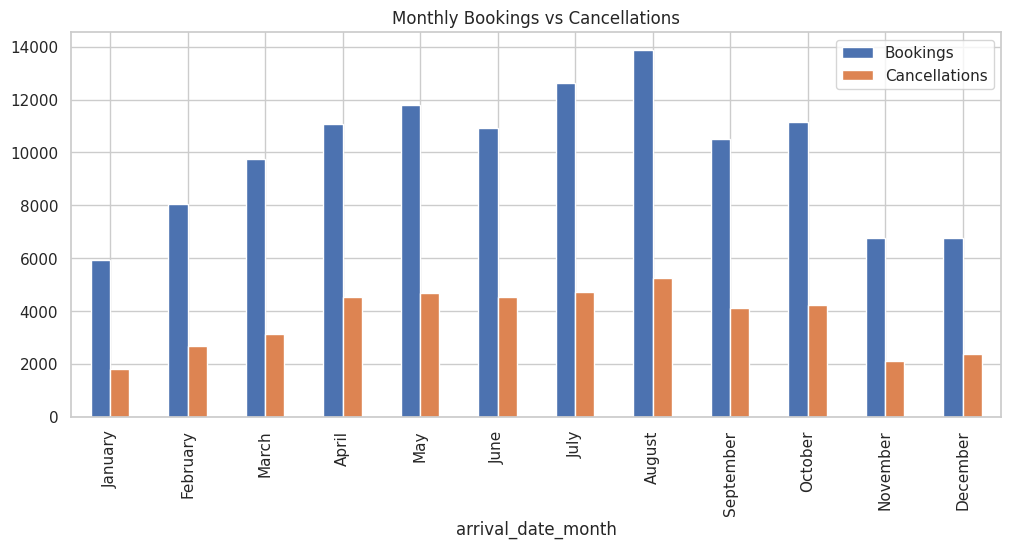

In [ ]:
months = ["January","February","March","April","May","June",
          "July","August","September","October","November","December"]

monthly = df.groupby("arrival_date_month")["is_canceled"].agg(["count","sum"]).reindex(months)
monthly.columns = ["Bookings", "Cancellations"]
monthly.plot(kind="bar", figsize=(12,5), title="Monthly Bookings vs Cancellations")
plt.show()

### Lead time

The earlier a booking is made, the more likely it is to be canceled: about 10% for bookings made less than a week ahead, about 68% for bookings made a year or more ahead.

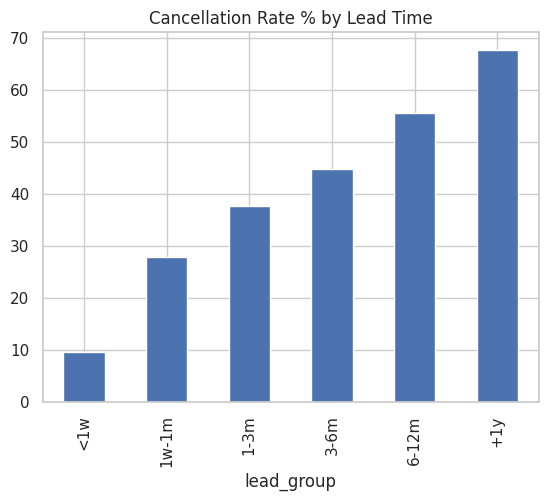

In [ ]:
df["lead_group"] = pd.cut(df["lead_time"], bins=[-1,7,30,90,180,365,800],
                          labels=["<1w","1w-1m","1-3m","3-6m","6-12m","+1y"])
(df.groupby("lead_group", observed=True)["is_canceled"].mean()*100).plot(
    kind="bar", title="Cancellation Rate % by Lead Time")
plt.show()

### Deposit type and booking channel

Non-refundable bookings cancel almost 100% of the time. This is counter-intuitive and is likely driven by bulk group bookings made by travel agencies.

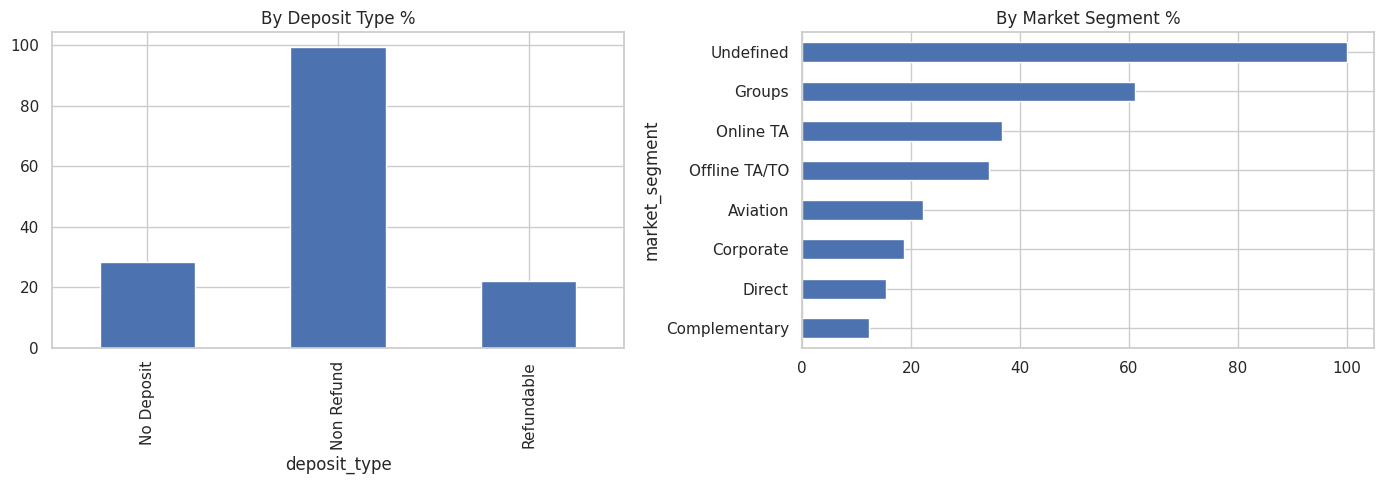

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
(df.groupby("deposit_type")["is_canceled"].mean()*100).plot(kind="bar", ax=ax[0], title="By Deposit Type %")
(df.groupby("market_segment")["is_canceled"].mean()*100).sort_values().plot(kind="barh", ax=ax[1], title="By Market Segment %")
plt.tight_layout(); plt.show()

### Where guests come from

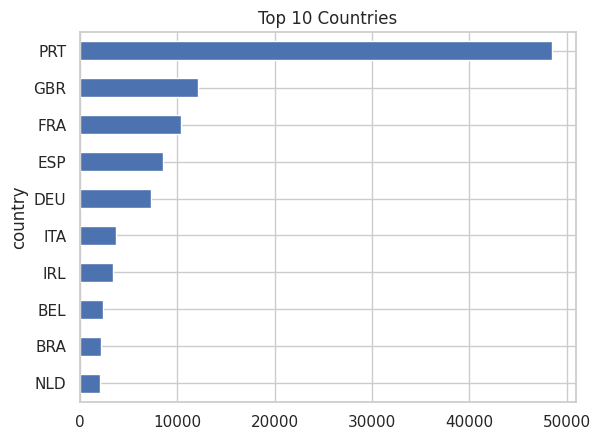

In [ ]:
df["country"].value_counts().head(10).plot(kind="barh", title="Top 10 Countries")
plt.gca().invert_yaxis(); plt.show()

## 5. Modeling

### Preparing the features

`reservation_status` and `reservation_status_date` directly reveal whether a booking was canceled, so they are removed to avoid **data leakage**. `assigned_room_type` is only known at check-in, so it is removed too.

In [ ]:
from sklearn.model_selection import train_test_split

# Keep the top 10 countries and group the rest as "Other"
top = df["country"].value_counts().head(10).index
df["country_grp"] = df["country"].where(df["country"].isin(top), "Other")

drop_cols = ["is_canceled", "reservation_status", "reservation_status_date",  # data leakage
             "assigned_room_type",                                             # only known at check-in
             "country", "agent", "lead_group", "revenue", "arrival_date_year"]

X = pd.get_dummies(df.drop(columns=drop_cols), drop_first=True)
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(95366, 67) (23842, 67)


### Logistic Regression vs Random Forest

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    print(f"{name}:  Accuracy={accuracy_score(y_test,pred):.3f}  "
          f"F1={f1_score(y_test,pred):.3f}  AUC={roc_auc_score(y_test,prob):.3f}")

Logistic Regression:  Accuracy=0.808  F1=0.709  AUC=0.886
Random Forest:  Accuracy=0.884  F1=0.836  AUC=0.953


### What drives cancellations?

Lead time, non-refundable deposits, price (ADR) and country are the strongest predictors.

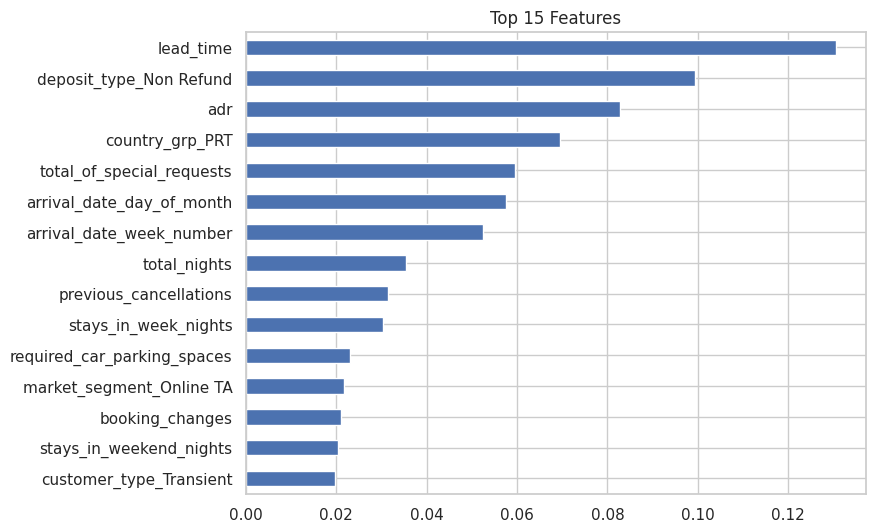

In [ ]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
imp.plot(kind="barh", figsize=(8,6), title="Top 15 Features")
plt.gca().invert_yaxis(); plt.show()

## 6. Export the clean data for Power BI

In [ ]:
df.to_csv("hotel_clean.csv", index=False)
from google.colab import files
files.download("hotel_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Lighter model for the Streamlit app

A smaller Random Forest trained on 12 easy-to-enter features, so anyone can try the app without filling in every column. It is saved as `model.pkl`.

In [ ]:
import os
import joblib
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

df = pd.read_csv("hotel_clean.csv")

NUM = ["lead_time", "adr", "total_nights", "adults", "total_of_special_requests",
       "previous_cancellations", "booking_changes", "required_car_parking_spaces"]
CAT = ["hotel", "deposit_type", "market_segment", "customer_type"]

X = df[NUM + CAT]
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = Pipeline([
    ("prep", ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore"), CAT)],
        remainder="passthrough")),
    ("rf", RandomForestClassifier(
        n_estimators=150, max_depth=18, min_samples_leaf=5,
        random_state=42, n_jobs=-1)),
])
model.fit(X_train, y_train)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
print(f"Accuracy = {accuracy_score(y_test, pred):.3f}")
print(f"F1       = {f1_score(y_test, pred):.3f}")
print(f"ROC-AUC  = {roc_auc_score(y_test, prob):.3f}")

joblib.dump(model, "model.pkl", compress=3)
print(f"model.pkl size: {os.path.getsize('model.pkl') / 1e6:.1f} MB")  # keep it under 25 MB
print("scikit-learn version:", sklearn.__version__)  # copy this into requirements.txt


Accuracy = 0.832
F1       = 0.743
ROC-AUC  = 0.904
model.pkl size: 10.1 MB
scikit-learn version: 1.6.1


## Results

| Model | Accuracy | F1 | ROC-AUC |
|---|---|---|---|
| Logistic Regression | 80.8% | 0.709 | 0.886 |
| Random Forest (all features) | 88.4% | 0.836 | 0.953 |
| Random Forest (app, 12 features) | 83.2% | 0.743 | 0.904 |

## Key insights

- 37% of bookings were canceled, costing about €16.7M in lost revenue.
- Bookings made 1+ year ahead cancel 68% of the time, versus 10% for bookings made less than a week ahead.
- The City Hotel cancels more often (42%) than the Resort Hotel (28%).
- Non-refundable deposits show about 99% cancellation.
- Lead time is the strongest predictor of cancellation.